# Figure 4 (combined)

Panels: a (feature ablation boxplot + dot grid), b (global grouped boxplot), c (exact Shapley),
f/h (compound proteomics ablation). Molecule panels (d/e/g) are left blank.


In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure code_repository/notebooks is importable
HERE = Path.cwd().resolve()
if (HERE / 'notebooks').exists():
    SRC_ROOT = HERE / 'notebooks'
elif (HERE / 'code_repository' / 'notebooks').exists():
    SRC_ROOT = HERE / 'code_repository' / 'notebooks'
elif (HERE.parent / 'code_repository' / 'notebooks').exists():
    SRC_ROOT = HERE.parent / 'code_repository' / 'notebooks'
else:
    SRC_ROOT = None
if SRC_ROOT is not None:
    sys.path.insert(0, str(SRC_ROOT))

from analysis.plot_style import apply_style, style_axes, save_figure, set_save_dir
from analysis.figure4_best_helpers import (
    _collect_balanced_long as _collect_balanced_long_impl,
    _posthoc_conover_friedman_vs_best as _posthoc_conover_friedman_vs_best_impl,
)

apply_style()

ROOT = Path.cwd().resolve()
if (ROOT / 'Data').exists():
    PROJECT_ROOT = ROOT
elif (ROOT.parent / 'Data').exists():
    PROJECT_ROOT = ROOT.parent
else:
    PROJECT_ROOT = ROOT

FIGURE_ID = 'figure4'
SAVE_DIR = set_save_dir(PROJECT_ROOT, FIGURE_ID)


In [2]:
import math
import os
import glob
import matplotlib.patches as mpatches


def plot_feature_ablation_panel(
    ax_box: plt.Axes,
    ax_feat: plt.Axes,
    resample_df: pd.DataFrame,
    pval_matrix: pd.DataFrame,
    value_metric: str = 'pr_auc',
    alpha: float = 0.05,
    title: str | None = None,
    friedman_p_override: float | None = None,
    show_points: str = 'outliers',
    whis: float = 1.5,
    feature_separator: str = '+',
    plus_fontsize: int = 8,
    feature_label_fontsize: int = 9,
) -> None:
    def _fmt_p(p):
        return f"{p:.3g}" if p >= 1e-3 else f"{p:.1e}"

    df = resample_df[['var_tag', 'cv_cycle', value_metric]].dropna().copy()
    if df.empty:
        raise ValueError('resample_df is empty after dropping NaNs.')

    means = df.groupby('var_tag')[value_metric].mean().sort_values(ascending=False)
    order = means.index.tolist()
    best = order[0]
    best_mean = float(means.iloc[0])
    n_tags = len(order)

    palette = []
    for tag in order:
        if tag == best:
            palette.append('#1f77b4')
        else:
            if (best in pval_matrix.index) and (tag in pval_matrix.columns):
                q = pval_matrix.loc[best, tag]
            else:
                q = np.nan
            if (not np.isnan(q)) and (q < alpha) and (means.loc[tag] < best_mean):
                palette.append('#c45c5c')
            else:
                palette.append('#9e9e9e')

    p_show = friedman_p_override
    if p_show is None:
        try:
            import pingouin as pg
            friedman_table = pg.friedman(
                data=df.rename(columns={value_metric: 'value'}),
                dv='value', within='var_tag', subject='cv_cycle'
            )
            if 'p-unc' in friedman_table.columns:
                p_show = float(friedman_table['p-unc'].iloc[0])
            elif 'p' in friedman_table.columns:
                p_show = float(friedman_table['p'].iloc[0])
        except Exception:
            p_show = None

    # Feature incidence matrix
    tag_to_features = {}
    feature_universe = set()
    for vt in order:
        if vt == '(Text only)':
            feats_here = set()
        else:
            parts = [p.strip() for p in vt.split(feature_separator) if p.strip()]
            feats_here = set(parts)
        tag_to_features[vt] = feats_here
        feature_universe.update(feats_here)

    preferred_order_internal = ['Proteomics', 'ECFP', 'CellPaint', 'GC', 'MIC']
    feature_list = [f for f in preferred_order_internal if f in feature_universe]
    remaining = sorted(f for f in feature_universe if f not in feature_list)
    feature_list.extend(remaining)

    incidence_matrix = np.zeros((len(feature_list), n_tags), dtype=int)
    internal_index = {feat: i for i, feat in enumerate(feature_list)}
    for j, vt in enumerate(order):
        feats = tag_to_features[vt]
        for feat in feats:
            if feat in internal_index:
                i = internal_index[feat]
                incidence_matrix[i, j] = 1

    # Boxplot (top)
    sns.boxplot(
        data=df, x='var_tag', y=value_metric, order=order,
        whis=whis, fliersize=2,
        showfliers=(show_points != 'outliers'),
        palette=palette, ax=ax_box
    )

    if show_points == 'all':
        sns.stripplot(
            data=df, x='var_tag', y=value_metric, order=order,
            color='k', alpha=0.25, size=2, jitter=0.15, ax=ax_box
        )
    elif show_points == 'outliers':
        outs = []
        for tag, g in df.groupby('var_tag'):
            q1 = g[value_metric].quantile(0.25)
            q3 = g[value_metric].quantile(0.75)
            iqr = q3 - q1
            lo = q1 - whis * iqr
            hi = q3 + whis * iqr
            og = g[(g[value_metric] < lo) | (g[value_metric] > hi)].copy()
            outs.append(og)
        outs = pd.concat(outs, ignore_index=True) if outs else df.iloc[0:0]
        if not outs.empty:
            sns.stripplot(
                data=outs, x='var_tag', y=value_metric, order=order,
                color='k', alpha=0.6, size=2.5, jitter=0.15, ax=ax_box
            )

    # Align dot grid to actual box centers (robust to tick changes)
    boxes = [p for p in ax_box.patches if isinstance(p, mpatches.PathPatch)]
    centers = []
    for b in boxes:
        verts = b.get_path().vertices
        xmin, xmax = float(np.min(verts[:, 0])), float(np.max(verts[:, 0]))
        centers.append((xmin + xmax) / 2.0)
    if len(centers) >= n_tags:
        # seaborn draws boxes in order; take the first n_tags
        centers = centers[:n_tags]
    else:
        centers = ax_box.get_xticks()
        if len(centers) != n_tags:
            centers = np.arange(n_tags)

    tag_to_x = {tag: centers[i] for i, tag in enumerate(order)}
    if n_tags > 1:
        diffs = np.diff(sorted(centers))
        dx = float(np.median(diffs)) if len(diffs) else 1.0
    else:
        dx = 1.0
    ax_box.set_xlim(centers[0] - 0.5 * dx, centers[-1] + 0.5 * dx)
    ax_box.set_xticks(centers)

    ax_box.axhline(best_mean, color='#1f77b4', linestyle='--', linewidth=1, alpha=0.9)
    metric_label = value_metric.replace('_', ' ').upper()
    ax_box.set_ylabel(metric_label)
    base_title = title or f"{metric_label} by feature set"
    ax_box.set_title(base_title)
    ax_box.grid(True, axis='y', alpha=0.3)

    ax_box.set_xticklabels([])
    ax_box.set_xlabel('')

    style_axes(ax_box)

    # Feature grid (bottom)
    n_feat, _ = incidence_matrix.shape
    ax_feat.set_xlim(ax_box.get_xlim())
    ax_feat.set_facecolor('white')
    ax_feat.set_ylim(-0.5, n_feat - 0.5)

    xs, ys = [], []
    for j, vt in enumerate(order):
        x = tag_to_x[vt]
        for i in range(n_feat):
            if incidence_matrix[i, j] == 1:
                xs.append(x)
                ys.append(i)

    ax_feat.scatter(
        xs, ys,
        s=(plus_fontsize + 2) ** 2,
        marker='o',
        color='black',
        linewidths=0,
    )

    disp_map = {'CellPaint': 'InfoAlign'}
    y_labels = [disp_map.get(f, f) for f in feature_list]
    ax_feat.set_yticks(np.arange(n_feat))
    ax_feat.set_yticklabels(y_labels, fontsize=feature_label_fontsize)
    ax_feat.invert_yaxis()

    ax_feat.set_xticks([])
    ax_feat.grid(False)
    ax_feat._skip_style_axes = True
    ax_feat.set_xlabel('')
    ax_feat.tick_params(axis='both', which='both', length=0)
    for spine in ax_feat.spines.values():
        spine.set_visible(False)

    # Match x-position/width with the boxplot axis so dots align under ticks
    box_pos = ax_box.get_position()
    feat_pos = ax_feat.get_position()
    ax_feat.set_position([box_pos.x0, feat_pos.y0, box_pos.width, feat_pos.height])


def plot_grouped_global_best(ax: plt.Axes, metric: str = 'pr_auc') -> None:
    BASE_OUTDIR = PROJECT_ROOT / 'analysis_exports' / 'Feature_augmentation_experiment'
    MODEL_ORDER = ['rf', 'lightgbm', 'xgboost', 'mlp', 'pytorch_mlp', 'tabm']
    FEATURES = [
        'CellPaint+ECFP+Proteomics',
        'CellPaint+ECFP+MIC+Proteomics',
        'CellPaint+ECFP+GC+MIC+Proteomics',
    ]
    FEATURE_SHORT = {
        'CellPaint+ECFP+Proteomics': 'CP+ECFP+Prot',
        'CellPaint+ECFP+MIC+Proteomics': 'CP+ECFP+MIC+Prot',
        'CellPaint+ECFP+GC+MIC+Proteomics': 'CP+ECFP+GC+MIC+Prot',
    }
    ALPHA = 0.05

    C_RED = '#c45c5c'
    C_BLUE = '#1f77b4'
    C_GREY = '#9e9e9e'
    HATCH_MAP = {
        'CellPaint+ECFP+Proteomics': '',
        'CellPaint+ECFP+MIC+Proteomics': 'ooo',
        'CellPaint+ECFP+GC+MIC+Proteomics': 'xx',
    }

    long = _collect_balanced_long_impl(metric, BASE_OUTDIR, MODEL_ORDER, FEATURES)
    if long.empty:
        raise RuntimeError(f'No balanced data found for {metric} in {BASE_OUTDIR}')

    def _lab(m, f):
        return f"{m} | {FEATURE_SHORT[f]}"

    long = long.copy()
    long['cond'] = long.apply(lambda r: _lab(r['model_type'], r['feature_set']), axis=1)

    wide = long.pivot_table(index='cv_cycle', columns='cond', values='value', aggfunc='mean').dropna(axis=0, how='any')
    best_label, means, Q = _posthoc_conover_friedman_vs_best_impl(wide, alpha=ALPHA)

    present_models = [m for m in MODEL_ORDER if m in long['model_type'].unique().tolist()]
    group_gap = 1.2
    offsets = [-0.6, 0.0, 0.6]
    box_width = 0.6

    best_mean = float(means.loc[best_label]) if best_label is not None else np.nan
    color_map = {}
    for cond in wide.columns:
        if cond == best_label:
            color_map[cond] = C_BLUE
        else:
            q = Q.loc[best_label, cond] if (best_label in Q.index and cond in Q.columns) else np.nan
            color_map[cond] = C_RED if (not np.isnan(q)) and (q < ALPHA) and (means.loc[cond] < best_mean) else C_GREY

    xpos_map, xpos = {}, 0.0
    for m in present_models:
        xpos_map[m] = xpos
        xpos += (offsets[-1] - offsets[0]) + group_gap

    try:
        import pingouin as pg
        fried = pg.friedman(
            data=long.rename(columns={'value':'value'})[['cv_cycle', 'cond', 'value']],
            dv='value', within='cond', subject='cv_cycle'
        )
        fried_p = float(fried.filter(like='p').iloc[0,0])
    except Exception:
        fried_p = np.nan

    for m in present_models:
        for f, dx in zip(FEATURES, offsets):
            cond = _lab(m, f)
            if cond not in wide.columns:
                continue
            vals = wide[cond].dropna().values
            cx = xpos_map[m] + dx
            bp = ax.boxplot([vals], positions=[cx], widths=box_width,
                            patch_artist=True, showfliers=False,
                            medianprops=dict(linewidth=1.2, color='black'),
                            boxprops=dict(linewidth=1, color='black'),
                            whiskerprops=dict(linewidth=1, color='black'),
                            capprops=dict(linewidth=1, color='black'))
            for patch in bp['boxes']:
                patch.set_facecolor(color_map.get(cond, C_GREY))
                patch.set_edgecolor('black')
                patch.set_linewidth(1)

            # Editable patterns (avoid hatch for SVG/PDF editing)
            verts = bp['boxes'][0].get_path().vertices
            xmin, xmax = float(verts[:, 0].min()), float(verts[:, 0].max())
            ymin, ymax = float(verts[:, 1].min()), float(verts[:, 1].max())
            pad_x = 0.08 * (xmax - xmin)
            pad_y = 0.10 * (ymax - ymin)
            if f == 'CellPaint+ECFP+MIC+Proteomics':
                xs = [xmin + pad_x, (xmin + xmax) / 2.0, xmax - pad_x]
                ys = [ymin + pad_y, (ymin + ymax) / 2.0, ymax - pad_y]
                for yy in ys:
                    for xx in xs:
                        ax.plot([xx], [yy], marker='o', markersize=2.2, color='black',
                                linestyle='None', clip_path=bp['boxes'][0])
            elif f == 'CellPaint+ECFP+GC+MIC+Proteomics':
                ax.plot([xmin + pad_x, xmax - pad_x], [ymin + pad_y, ymax - pad_y],
                        color='black', lw=0.8, clip_path=bp['boxes'][0])
                ax.plot([xmin + pad_x, xmax - pad_x], [ymax - pad_y, ymin + pad_y],
                        color='black', lw=0.8, clip_path=bp['boxes'][0])

            # optional outlier dots
            q1, q3 = np.percentile(vals, [25, 75])
            iqr = q3 - q1
            lo = q1 - 1.5 * iqr
            hi = q3 + 1.5 * iqr
            pts = vals[(vals < lo) | (vals > hi)]
            if len(pts):
                xx = cx + (np.random.rand(len(pts)) - 0.5) * 0.22
                ax.scatter(xx, pts, s=12, alpha=0.6, color='black', linewidths=0)

    ax.set_xticks([xpos_map[m] for m in present_models])
    ax.set_xticklabels(present_models)
    metric_label = metric.replace('_', ' ').upper()
    ax.set_ylabel(metric_label)
    ax.set_title(f"{metric_label} by model and feature set")

    style_axes(ax)


def plot_shapley_ax(ax: plt.Axes, shap_df: pd.DataFrame, title: str) -> None:
    df = shap_df.copy()
    # Keep terminology consistent across Figure 4.
    df['feature'] = df['feature'].astype(str).str.replace('CellPaint', 'InfoAlign', regex=False)
    df = df.sort_values('shapley', ascending=True)

    palette = sns.color_palette('mako', n_colors=len(df))
    ax.barh(df['feature'], df['shapley'], color=palette)
    ax.axvline(0.0, linestyle='--', linewidth=1)
    ax.set_xlabel('Shapley value (contribution to payoff)')
    ax.set_ylabel('Feature')
    ax.set_title(title)
    ax.set_xlim(df['shapley'].min() - 0.05, df['shapley'].max() + 0.05)
    ax.grid(True, axis='x', alpha=0.3)
    for y, v in enumerate(df['shapley'].values):
        ax.text(v + (0.01 if v >= 0 else -0.01), y, f'{v:.3f}',
                va='center', ha='left' if v >= 0 else 'right')
    style_axes(ax)


def plot_compound_modality_two_jumps(ax: plt.Axes, compound_id: str, delta_label_mode: str = 'under') -> None:
    # Kept delta_label_mode for backward compatibility with existing call sites.
    SPLIT_TASK = 'binary_loo_ablation'

    RUN_SPECS = {
        'ecfp_cp': {
            'label': 'IA+ECFP',
            'exp': 'Uncertainty_experiment_semantic_ecfp_cp',
            'run': 'semantic_BioBERT_tabm_Text_Embedding+ECFP+CellPaint',
        },
        'ecfp_cp_prot': {
            'label': 'IA+ECFP+\nProt',
            'exp': 'Uncertainty_experiment_semantic_prot_ecfp_cp',
            'run': 'semantic_BioBERT_tabm_Text_Embedding+Proteomics+ECFP+CellPaint',
        },
        'all_modalities': {
            'label': 'IA+ECFP+\nProt+MIC+GC',
            'exp': 'Uncertainty_experiment_semantic',
            'run': 'semantic_BioBERT_tabm_Text_Embedding+Proteomics+ECFP+CellPaint+MIC+GC',
        },
    }

    COLORS = ['#264653','#287271','#2a9d8f','#8ab17d',
              '#e9c46a','#efb366','#f4a261','#ee8959','#e76f51']
    DISPLAY_ORDER = [
        'Fatty acid','Nitrofurans','Folic acid','Membrane',
        'RNA synth.','LPS synth.','DNA repl.','Cell wall','Protein syn.'
    ]

    CANON_MAP = {
        'Fatty acid':      ['Fatty acid','Fatty acid synthesis'],
        'Nitrofurans':     ['Nitrofurans'],
        'Folic acid':      ['Folic acid','Folic acid metabolism','Folic acid biosynthesis'],
        'Membrane':        ['Membrane','Membrane disruption','Membrane integrity'],
        'RNA synth.':      ['RNA synth.','RNA Synthesis','RNA synthesis'],
        'LPS synth.':      ['LPS synth.','lipopolysaccharide synthesis','LPS synthesis'],
        'DNA repl.':       ['DNA repl.','DNA replication','DNA Replication'],
        'Cell wall':       ['Cell wall','Cell wall biosynthesis','Cell-wall biosynthesis'],
        'Protein syn.':    ['Protein syn.','Protein synthesis','Protein Synthesis'],
    }
    SYN_TO_DISPLAY = {syn.lower(): disp for disp, syns in CANON_MAP.items() for syn in syns}

    def map_to_display(m):
        if m is None:
            return None
        return SYN_TO_DISPLAY.get(str(m).strip().lower())

    run_dirs = {
        k: PROJECT_ROOT / 'predictions' / spec['exp'] / SPLIT_TASK / spec['run']
        for k, spec in RUN_SPECS.items()
    }

    def load_all_pickles(run_dir: Path) -> pd.DataFrame:
        files = sorted(run_dir.glob('fold*_rep*_seed*.pkl'))
        if not files:
            raise FileNotFoundError(f'No fold PKLs in {run_dir}')
        dfs = []
        for fp in files:
            try:
                dfs.append(pd.read_pickle(fp))
            except Exception as e:
                print(f'Skipping {fp}: {e}')
        if not dfs:
            raise RuntimeError(f'Loaded 0 DataFrames from {run_dir}')
        df = pd.concat(dfs, axis=0, ignore_index=False)
        if 'SampleID' not in df.columns:
            if df.index.name == 'SampleID':
                df = df.reset_index()
            else:
                raise ValueError('No SampleID in prediction frames.')
        return df

    def replicate_values_by_moa(df: pd.DataFrame, comp_id: str) -> dict[str, np.ndarray]:
        vals: dict[str, list[np.ndarray]] = {}
        msk = df['SampleID'].astype(str).str.startswith(str(comp_id) + '_')

        if ('CandidateMoA' in df.columns) and ('ProbaPos' in df.columns):
            sub = df.loc[msk, ['CandidateMoA', 'ProbaPos']].dropna()
            for moa, arr in sub.groupby('CandidateMoA')['ProbaPos']:
                disp = map_to_display(moa)
                if disp is None:
                    continue
                vals.setdefault(disp, []).append(arr.to_numpy(dtype=float))
        else:
            prob_cols = [c for c in df.columns if c.startswith('proba_')]
            if not prob_cols:
                raise ValueError('No pairwise or multiclass proba columns found.')
            sub = (
                df.loc[msk, ['SampleID'] + prob_cols]
                  .melt(id_vars='SampleID', var_name='MoA', value_name='Proba')
                  .dropna()
            )
            sub['MoA'] = sub['MoA'].str.replace('^proba_', '', regex=True)
            for moa, arr in sub.groupby('MoA')['Proba']:
                disp = map_to_display(moa)
                if disp is None:
                    continue
                vals.setdefault(disp, []).append(arr.to_numpy(dtype=float))

        out = {}
        for k in vals:
            out[k] = np.concatenate(vals[k], axis=0) if vals[k] else np.array([], dtype=float)
        return out

    def summarize(vals_dict: dict[str, np.ndarray], order: list[str]) -> pd.DataFrame:
        rows = []
        for moa in order:
            arr = vals_dict.get(moa, np.array([], dtype=float))
            if arr.size == 0:
                rows.append({'MoA': moa, 'n': 0, 'mean': np.nan, 'std': np.nan, 'sem': np.nan})
            else:
                std = float(np.std(arr, ddof=1)) if arr.size > 1 else 0.0
                rows.append({
                    'MoA': moa,
                    'n': int(arr.size),
                    'mean': float(np.mean(arr)),
                    'std': std,
                    'sem': float(std / np.sqrt(arr.size)) if arr.size > 1 else 0.0,
                })
        return pd.DataFrame(rows)

    summaries = {}
    for key in ['ecfp_cp', 'ecfp_cp_prot', 'all_modalities']:
        df = load_all_pickles(run_dirs[key])
        vals = replicate_values_by_moa(df, compound_id)
        summaries[key] = summarize(vals, DISPLAY_ORDER)

    from data_processing.chemistry import prepare_compound_data_from_excels
    xlsx = PROJECT_ROOT / 'Data' / '250808_compounds.xlsx'
    compound_dict = prepare_compound_data_from_excels(
        growth_curve_file=str(xlsx),
        mic_file=str(xlsx),
        smiles_file=str(xlsx),
        output_pickle_path=None,
    )

    true_moa_raw = compound_dict.get(compound_id, {}).get('mode_of_action')
    true_moa_disp = map_to_display(true_moa_raw) if true_moa_raw else None
    true_idx = DISPLAY_ORDER.index(true_moa_disp) if true_moa_disp in DISPLAY_ORDER else None

    color_map = {moa: COLORS[i % len(COLORS)] for i, moa in enumerate(DISPLAY_ORDER)}

    group_keys = ['ecfp_cp', 'ecfp_cp_prot', 'all_modalities']
    group_labels = [RUN_SPECS[k]['label'] for k in group_keys]
    group_centers = np.array([0.0, 0.55, 1.10])
    K = len(DISPLAY_ORDER)
    group_width = 0.40
    bar_width = group_width / K
    offsets = (-group_width / 2) + (np.arange(K) + 0.5) * bar_width

    for gi, key in enumerate(group_keys):
        s = summaries[key]
        x = group_centers[gi] + offsets
        ax.bar(
            x,
            s['mean'].values,
            yerr=s['sem'].values,
            capsize=3,
            width=bar_width,
            color=[color_map[m] for m in DISPLAY_ORDER],
            edgecolor='none',
            zorder=2,
        )

    # start from standard panel range; expand only if needed
    ax.set_ylim(0.0, 1.2)
    ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])

    floor = 0.025
    dot_size = 12
    for gi, key in enumerate(group_keys):
        x = group_centers[gi] + offsets
        for j, moa in enumerate(DISPLAY_ORDER):
            mu = summaries[key].loc[j, 'mean']
            if np.isfinite(mu):
                ydot = floor * (1.00 + 0.02 * gi)
                ax.plot([x[j]], [ydot], marker='o', color=color_map[moa], alpha=0.9,
                        markersize=math.sqrt(dot_size), zorder=4)

    if true_idx is not None:
        x_true = [float(group_centers[g] + offsets[true_idx]) for g in range(3)]

        means = [
            float(summaries['ecfp_cp'].loc[true_idx, 'mean']),
            float(summaries['ecfp_cp_prot'].loc[true_idx, 'mean']),
            float(summaries['all_modalities'].loc[true_idx, 'mean']),
        ]
        sems = [
            float(summaries['ecfp_cp'].loc[true_idx, 'sem']),
            float(summaries['ecfp_cp_prot'].loc[true_idx, 'sem']),
            float(summaries['all_modalities'].loc[true_idx, 'sem']),
        ]
        tops = [m + s for m, s in zip(means, sems)]

        ymin, ymax = ax.get_ylim()
        yspan = max(1e-6, ymax - ymin)
        hover_pad = 0.050 * yspan
        min_stem = 0.050 * yspan
        extra_head = 0.10 * yspan
        text_drop = 0.014 * yspan
        min_base = floor + 0.020

        def draw_jump(i_left: int, i_right: int, label: str, level_boost: float = 0.0, left_base_lift: float = 0.0):
            xl, xr = x_true[i_left], x_true[i_right]
            y_left_base = max(tops[i_left] + hover_pad, min_base) + left_base_lift
            y_right_base = tops[i_right] + hover_pad
            y_h = max(y_left_base, y_right_base) + min_stem + level_boost

            ax.plot([xl, xl], [y_left_base, y_h], color='black', lw=1.2, zorder=6)
            ax.plot([xl, xr], [y_h, y_h], color='black', lw=1.2, zorder=6)
            ax.plot([xr, xr], [y_h, y_right_base], color='black', lw=1.2, zorder=6)
            ax.plot(
                [xr], [y_right_base],
                marker='v', markersize=6.5,
                color='black', markeredgecolor='black',
                zorder=7, clip_on=False,
            )

            delta = means[i_right] - means[i_left]
            delta_txt = f"{label}: {'+' if delta >= 0 else '-'}{abs(delta):.2f}"
            ax.text(
                (xl + xr) / 2,
                y_h - text_drop,
                delta_txt,
                ha='center',
                va='top',
                fontsize=9,
                fontweight='bold',
                color=('#2e7d32' if delta >= 0 else '#c62828'),
                zorder=7,
            )
            return y_h + extra_head

        top1 = draw_jump(0, 1, 'D1', level_boost=0.0, left_base_lift=0.0)
        top2 = draw_jump(1, 2, 'D2', level_boost=0.00 * yspan, left_base_lift=0.08 * yspan)
        need_top = max(top1, top2)
        if need_top > ymax:
            ax.set_ylim(ymin, need_top)

    ax.set_xticks(group_centers)
    ax.set_xticklabels(group_labels)
    ax.set_xlim(group_centers[0] - 0.35, group_centers[2] + 0.35)
    ax.set_ylabel('Predicted probability')

    cinfo = compound_dict.get(compound_id, {})
    compound_name = cinfo.get('name', compound_id)
    ax.set_title(f"{compound_name}" + (f"   |   True MoA: {true_moa_disp or true_moa_raw}" if true_moa_raw else ''))

    for spine in ['left', 'bottom', 'top', 'right']:
        ax.spines[spine].set_visible(True)
        ax.spines[spine].set_linewidth(1.2)
        ax.spines[spine].set_color('black')

    ax.grid(visible=False)
    style_axes(ax)





/tmp/ipykernel_7508/3493244394.py:91: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
2026-03-13 12:57:40.267335: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1773406660.279593    7508 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1773406660.283050    7508 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1773406660.292228    7508 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773406660.292

{'Ampicillin (sodium)': 'JH0', 'Amoxicillin': 'JH1', 'Sulopenem': 'JH2', 'Cefodizime': 'JH3', 'Aztreonam': 'JH4', 'Doripenem': 'JH5', 'Imipenem (monohydrate)': 'JH6', 'Ertapenem (disodium)': 'JH7', 'Cefiderocol': 'JH8', 'Cefepime': 'JH9', 'Fosfomycin (calcium)': 'JH10', 'Retapamulin': 'JH11', 'Framycetin (sulfate)': 'JH12', 'Chloramphenicol': 'JH13', 'Tigecycline': 'JH14', 'Tetracycline': 'JH15', 'Azithromycin': 'JH16', 'Gentamicin sulfate': 'JH17', 'Eravacycline (dihydrochloride)': 'JH18', 'Apramycin (sulfate)': 'JH19', 'Kanamycin sulfate': 'JH55', 'Tobramycine': 'JH56', 'Sulfamonomethoxine': 'JH20', 'Sulfisoxazole': 'JH21', 'Sulfacetamide': 'JH22', 'Trimethoprim': 'JH23', 'Tetroxoprim': 'JH24', 'Sulfaguanidine': 'JH25', 'Sulphanilamide': 'JH57', 'Sulfadiazine': 'JH63', 'Gatifloxacin': 'JH26', 'Temafloxacin': 'JH27', 'Lascufloxacin': 'JH28', 'Ciprofloxacin': 'JH29', 'Levofloxacin': 'JH30', 'Nitrofurantoin': 'JH31', 'Gepotidacin': 'JH32', 'Nalidixic acid': 'JH33', 'Novobiocin': 'JH34',

/tmp/ipykernel_7508/1653453405.py:138: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


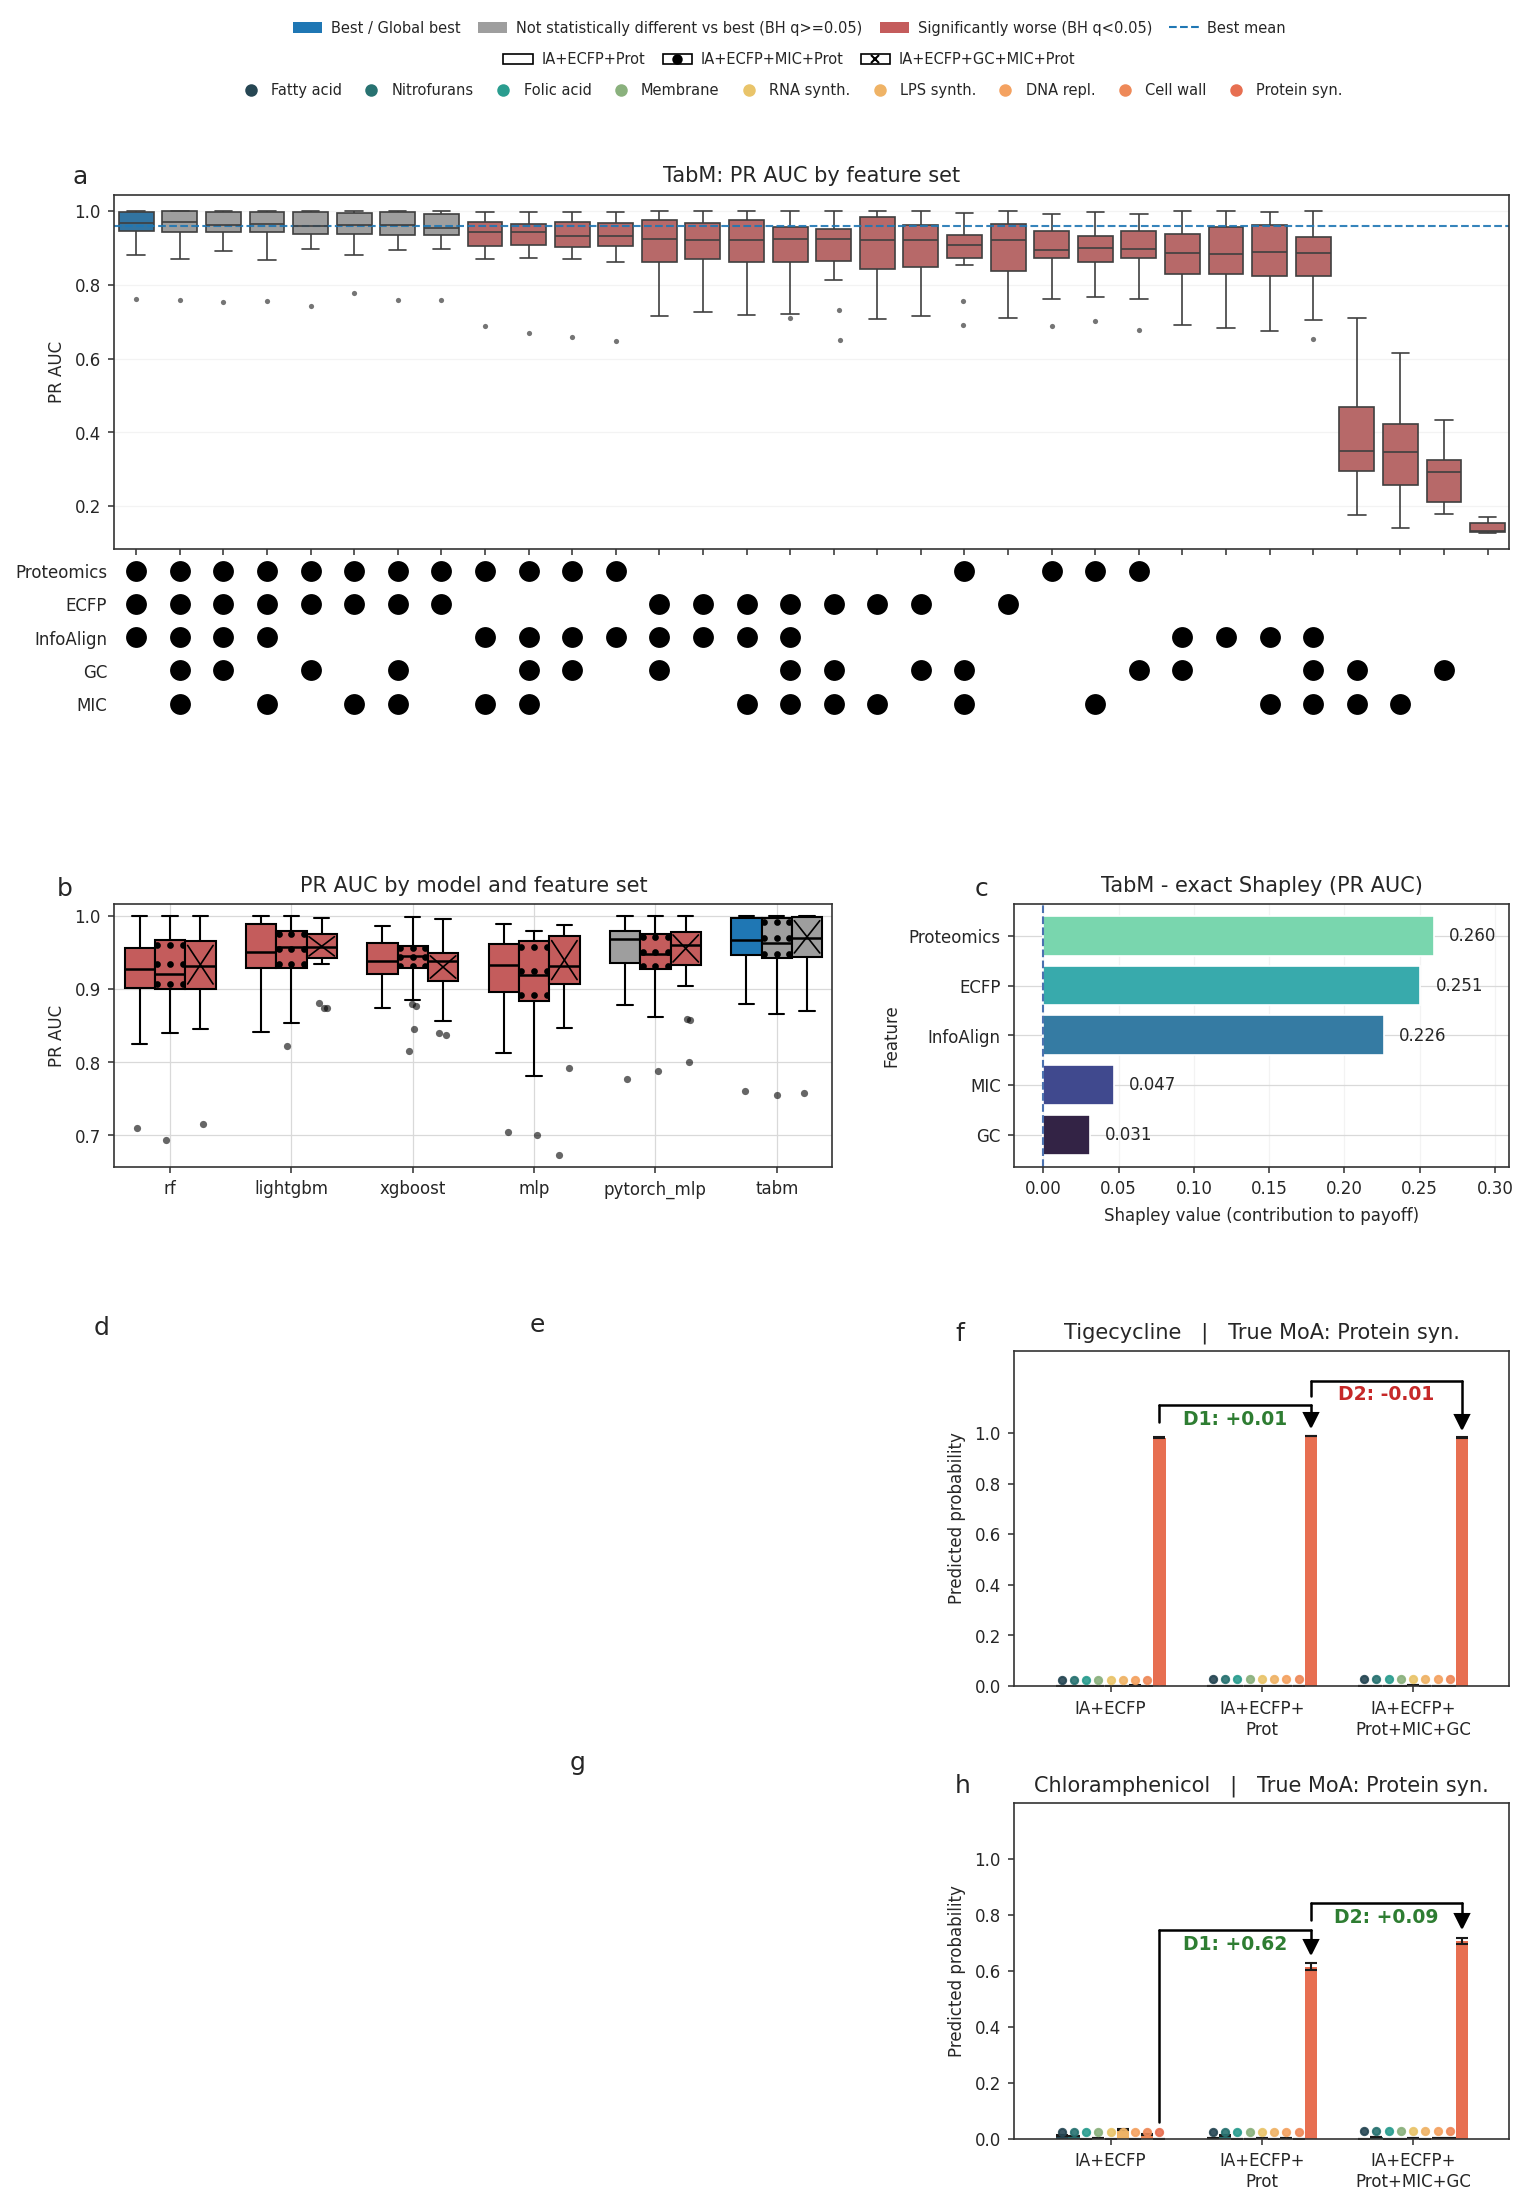

In [3]:
# ---- Load data sources ----
BASE_OUTDIR = PROJECT_ROOT / 'analysis_exports' / 'Feature_augmentation_experiment'
TABM_PR_DIR = BASE_OUTDIR / 'tabm' / 'pr_auc'

per_cycle_path = TABM_PR_DIR / 'tabm_per_cycle_pr_auc.csv'
pvals_path = TABM_PR_DIR / 'tabm_pairwise_pr_auc_pvals_BH.csv'
fried_path = TABM_PR_DIR / 'tabm_friedman_pr_auc.csv'

if not per_cycle_path.exists():
    raise FileNotFoundError(f'Missing {per_cycle_path}')
if not pvals_path.exists():
    raise FileNotFoundError(f'Missing {pvals_path}')

tabm_per_cycle = pd.read_csv(per_cycle_path)
tabm_pvals = pd.read_csv(pvals_path, index_col=0)

fried_p = None
if fried_path.exists():
    fried_df = pd.read_csv(fried_path)
    if 'p-unc' in fried_df.columns:
        fried_p = float(fried_df['p-unc'].iloc[0])

shap_path = PROJECT_ROOT / 'analysis_exports' / 'Feature_augmentation_experiment' / 'Shapley' / 'tabm_shapley_exact_pr_auc.csv'
if not shap_path.exists():
    raise FileNotFoundError(f'Missing {shap_path}')
shap_df = pd.read_csv(shap_path)

# ---- Build combined figure ----
from matplotlib.legend_handler import HandlerTuple

fig = plt.figure(figsize=(12, 16))
gs = fig.add_gridspec(3, 2, height_ratios=[2.0, 1, 3], width_ratios=[1.45, 1.0],
                     hspace=0.35, wspace=0.30)

# Panel a: top boxplot + dot grid
gs_a = gs[0, :].subgridspec(2, 1, height_ratios=[3.0, 1.4], hspace=0.02)
ax_a_top = fig.add_subplot(gs_a[0, 0])
ax_a_bot = fig.add_subplot(gs_a[1, 0])
plot_feature_ablation_panel(
    ax_a_top, ax_a_bot,
    tabm_per_cycle.rename(columns={'pr_auc':'pr_auc'}),
    tabm_pvals,
    value_metric='pr_auc',
    alpha=0.05,
    title='TabM: PR AUC by feature set',
    friedman_p_override=fried_p,
)

# Panel b and c
ax_b = fig.add_subplot(gs[1, 0])
plot_grouped_global_best(ax_b, metric='pr_auc')



ax_c = fig.add_subplot(gs[1, 1])
plot_shapley_ax(ax_c, shap_df, title='TabM - exact Shapley (PR AUC)')

# Panel d/e/g placeholders (molecules added later)
gs_left = gs[2, 0].subgridspec(2, 2, width_ratios=[1.6, 1.0], height_ratios=[1.0, 1.0],
                             wspace=0.10, hspace=0.10)
ax_d = fig.add_subplot(gs_left[:, 0])
ax_e = fig.add_subplot(gs_left[0, 1])
ax_g = fig.add_subplot(gs_left[1, 1])
for ax in [ax_d, ax_e, ax_g]:
    ax.axis('off')

# Panel f/h (compound proteomics ablation)
gs_right = gs[2, 1].subgridspec(2, 1, hspace=0.35)
ax_f = fig.add_subplot(gs_right[0, 0])
ax_h = fig.add_subplot(gs_right[1, 0])
plot_compound_modality_two_jumps(ax_f, 'JH14', delta_label_mode='under')  # Temafloxacin
plot_compound_modality_two_jumps(ax_h, 'JH13', delta_label_mode='under')  # Gepotidacin

# Panel labels
ax_a_top.text(-0.03, 1.03, 'a', transform=ax_a_top.transAxes, fontsize=12, fontweight='normal')
ax_b.text(-0.08, 1.03, 'b', transform=ax_b.transAxes, fontsize=12, fontweight='normal')
ax_c.text(-0.08, 1.03, 'c', transform=ax_c.transAxes, fontsize=12, fontweight='normal')
ax_d.text(-0.05, 1.02, 'd', transform=ax_d.transAxes, fontsize=12, fontweight='normal')
ax_e.text(-0.15, 1.05, 'e', transform=ax_e.transAxes, fontsize=12, fontweight='normal')
ax_f.text(-0.12, 1.03, 'f', transform=ax_f.transAxes, fontsize=12, fontweight='normal')
g_pos = ax_g.get_position()
fig.text(g_pos.x0, g_pos.y1 + 0.005, 'g', fontsize=12, fontweight='normal')
ax_h.text(-0.12, 1.03, 'h', transform=ax_h.transAxes, fontsize=12, fontweight='normal')

# ---- Figure-level legends (top) ----
from matplotlib.legend_handler import HandlerBase
from matplotlib.lines import Line2D

class PatchWithMarker:
    def __init__(self, marker=None):
        self.marker = marker

class HandlerPatchWithMarker(HandlerBase):
    def create_artists(self, legend, orig_handle, xdescent, ydescent, width, height, fontsize, trans):
        patch = mpatches.Rectangle((xdescent, ydescent), width, height,
                                   facecolor='white', edgecolor='black', lw=1, transform=trans)
        artists = [patch]
        if orig_handle.marker is not None:
            marker = Line2D([xdescent + width / 2], [ydescent + height / 2],
                            marker=orig_handle.marker, color='black', linestyle='None',
                            markersize=fontsize * 0.6, transform=trans)
            artists.append(marker)
        return artists

moa_labels = ['Fatty acid','Nitrofurans','Folic acid','Membrane','RNA synth.','LPS synth.','DNA repl.','Cell wall','Protein syn.']
moa_colors = ['#264653','#287271','#2a9d8f','#8ab17d',
              '#e9c46a','#efb366','#f4a261','#ee8959','#e76f51']
moa_handles = [plt.Line2D([0],[0], marker='o', color=c, lw=0, markersize=5, label=lab)
               for lab, c in zip(moa_labels, moa_colors)]

# Significance (shared for panels a/b) + best mean line
signif_handles = [
    mpatches.Patch(facecolor='#1f77b4', edgecolor='none', label='Best / Global best'),
    mpatches.Patch(facecolor='#9e9e9e', edgecolor='none', label='Not statistically different vs best (BH q>=0.05)'),
    mpatches.Patch(facecolor='#c45c5c', edgecolor='none', label='Significantly worse (BH q<0.05)'),
    plt.Line2D([0],[0], color='#1f77b4', lw=1, ls='--', label='Best mean'),
]

# Feature set patterns (panel b) - show dot/x inside boxes
feat_box = mpatches.Patch(facecolor='white', edgecolor='black')
feat_dot = (mpatches.Patch(facecolor='white', edgecolor='black'),
            plt.Line2D([0],[0], marker='o', linestyle='None', color='black', markersize=4))
feat_x = (mpatches.Patch(facecolor='white', edgecolor='black'),
          plt.Line2D([0],[0], marker='x', linestyle='None', color='black', markersize=4))

fig.legend(handles=moa_handles, loc='upper center', ncol=9, frameon=False,
           bbox_to_anchor=(0.5, 0.972), handletextpad=0.4, columnspacing=1.0)
fig.legend(handles=signif_handles, loc='upper center', ncol=4, frameon=False,
           bbox_to_anchor=(0.5, 0.998), handletextpad=0.6, columnspacing=1.2)
fig.legend(handles=[feat_box, feat_dot, feat_x],
           labels=['IA+ECFP+Prot', 'IA+ECFP+MIC+Prot', 'IA+ECFP+GC+MIC+Prot'],
           loc='upper center', ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 0.985), handletextpad=0.6, columnspacing=1.2,
           handler_map={tuple: HandlerTuple(ndivide=1, pad=0.0)})

fig.subplots_adjust(top=0.92)

fig.tight_layout()
save_figure(fig, 'figure4_combined')
plt.show()


